<a href="https://colab.research.google.com/github/madhuriharinilece2025-jpg/ecg-signal-classification/blob/main/ECG_CLASSIFICATION_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("AI-Based ECG Signal Classification")
print("Welcome to my first AI project!")

AI-Based ECG Signal Classification
Welcome to my first AI project!


In [ ]:
!pip install wfdb scipy scikit-learn matplotlib pandas numpy

In [ ]:

from collections import Counter

print("Heartbeat counts:", Counter(y_new))

if len(X_new) > 0 and len(set(y_new)) == 2:
    print("Dataset is ready for the next step!")
else:
    print("Dataset needs fixing before training.")

Heartbeat counts: Counter({np.str_('N'): 57918, np.str_('V'): 6028})
Dataset is ready for the next step!


In [ ]:
from collections import Counter

print("Dataset shape:", X_new.shape)
print("Heartbeat counts:", Counter(y_new))

Dataset shape: (63946, 180)
Heartbeat counts: Counter({np.str_('N'): 57918, np.str_('V'): 6028})


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from collections import Counter
import numpy as np

# Check that both heartbeat classes are available
print("Heartbeat counts:", Counter(y_new))

# Convert labels: N = 0, V = 1
y_binary = np.array([0 if label == "N" else 1 for label in y_new])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_new, y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_binary
)

# Scale the signal values
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Data preparation complete!")

Heartbeat counts: Counter({np.str_('N'): 57918, np.str_('V'): 6028})
Training data: (51156, 180)
Testing data: (12790, 180)
Data preparation complete!


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Create the machine learning model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train the model
model.fit(X_train, y_train)

# Test the model
y_pred = model.predict(X_test)

# Display accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model training complete!")
print("Model accuracy:", round(accuracy * 100, 2), "%")

Model training complete!
Model accuracy: 99.37 %


Classification Report:
              precision    recall  f1-score   support

  Normal (N)       0.99      1.00      1.00     11584
Abnormal (V)       0.99      0.94      0.97      1206

    accuracy                           0.99     12790
   macro avg       0.99      0.97      0.98     12790
weighted avg       0.99      0.99      0.99     12790



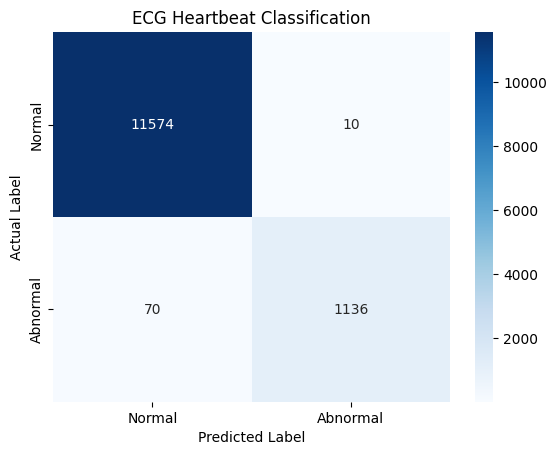

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Normal (N)", "Abnormal (V)"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Abnormal"],
    yticklabels=["Normal", "Abnormal"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("ECG Heartbeat Classification")
plt.show()

In [ ]:
import joblib

# Save the trained model and scaler
joblib.dump(model, "ecg_classification_model.pkl")
joblib.dump(scaler, "ecg_scaler.pkl")

print("ECG model saved successfully!")
print("Files: ecg_classification_model.pkl")
print("       ecg_scaler.pkl")

ECG model saved successfully!
Files: ecg_classification_model.pkl
       ecg_scaler.pkl


In [ ]:
from google.colab import files

files.download("ecg_classification_model.pkl")
files.download("ecg_scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import wfdb

record = wfdb.rdrecord("100", pn_dir="mitdb")

print("ECG data loaded successfully")
print("Signal shape:", record.p_signal.shape)
print("Sampling frequency:", record.fs)

ECG data loaded successfully
Signal shape: (650000, 2)
Sampling frequency: 360


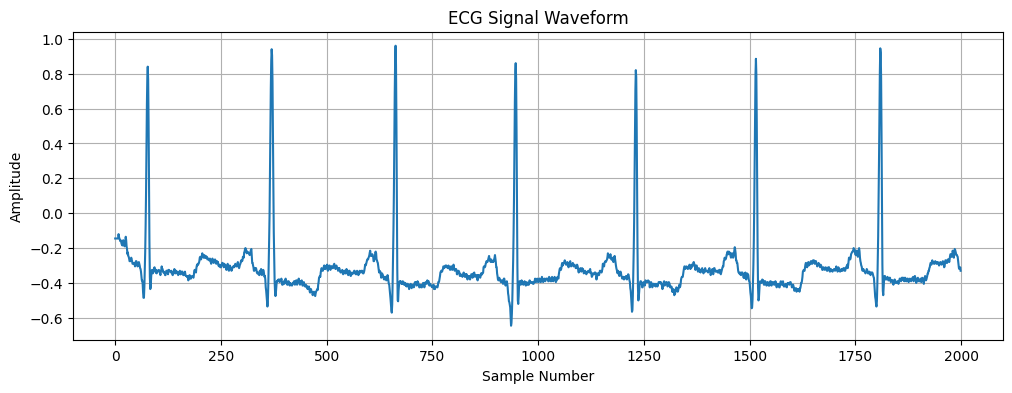

In [ ]:
import matplotlib.pyplot as plt

ecg_signal = record.p_signal[:, 0]

plt.figure(figsize=(12, 4))

plt.plot(ecg_signal[:2000])

plt.title("ECG Signal Waveform")
plt.xlabel("Sample Number")
plt.ylabel("Amplitude")

plt.grid(True)
plt.show()

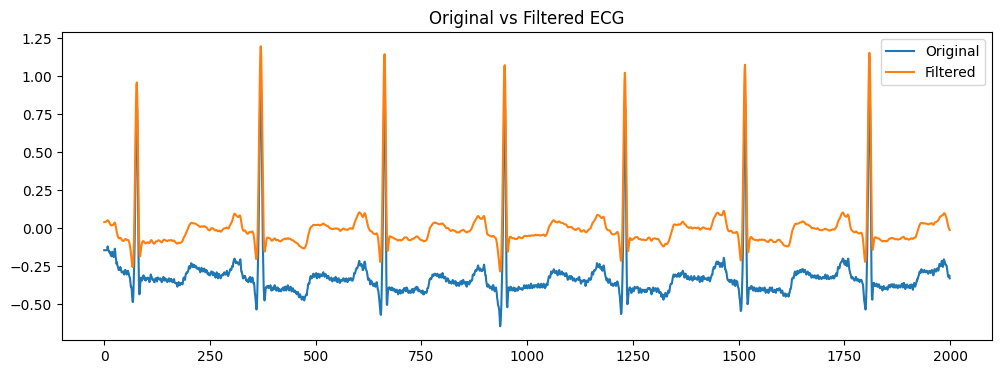

In [ ]:
from scipy.signal import butter, filtfilt

fs = record.fs

ecg_signal = record.p_signal[:, 0]

b, a = butter(
    2,
    [0.5, 40],
    btype="bandpass",
    fs=fs
)

filtered_signal = filtfilt(
    b,
    a,
    ecg_signal
)

plt.figure(figsize=(12, 4))

plt.plot(
    ecg_signal[:2000],
    label="Original"
)

plt.plot(
    filtered_signal[:2000],
    label="Filtered"
)

plt.title("Original vs Filtered ECG")
plt.legend()
plt.show()

In [ ]:
import numpy as np

features = {
    "Mean": np.mean(filtered_signal),
    "Standard Deviation": np.std(filtered_signal),
    "Minimum": np.min(filtered_signal),
    "Maximum": np.max(filtered_signal)
}

for name, value in features.items():
    print(name, ":", value)

Mean : 2.40289398115479e-06
Standard Deviation : 0.1791597523356455
Minimum : -2.455114463316181
Maximum : 2.86882830716285


In [ ]:
import wfdb
import numpy as np
import pandas as pd

# Load ECG heartbeat annotations
annotation = wfdb.rdann(
    "100",
    "atr",
    pn_dir="mitdb"
)

print("ECG annotations loaded successfully")
print("Number of annotated heartbeats:", len(annotation.sample))

print("First 10 heartbeat positions:")
print(annotation.sample[:10])

print("First 10 heartbeat labels:")
print(annotation.symbol[:10])

ECG annotations loaded successfully
Number of annotated heartbeats: 2274
First 10 heartbeat positions:
[  18   77  370  662  946 1231 1515 1809 2044 2402]
First 10 heartbeat labels:
['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N']


In [ ]:
import numpy as np
import pandas as pd

# ECG signal and annotations are already loaded
signal = record.p_signal[:, 0]
positions = annotation.sample
labels = annotation.symbol

# Select heartbeat categories for this first model
selected_classes = ["N", "V"]

X = []
y = []

# Take a small section around each heartbeat
for pos, label in zip(positions, labels):

    if label not in selected_classes:
        continue

    start = pos - 90
    end = pos + 90

    if start < 0 or end > len(signal):
        continue

    heartbeat = signal[start:end]

    X.append(heartbeat)
    y.append(label)

X = np.array(X)
y = np.array(y)

print("Dataset prepared successfully!")
print("Number of heartbeats:", len(X))
print("Heartbeat segment shape:", X.shape)
print("Classes:", np.unique(y))
print("Class counts:")
print(pd.Series(y).value_counts())

Dataset prepared successfully!
Number of heartbeats: 2238
Heartbeat segment shape: (2238, 180)
Classes: ['N' 'V']
Class counts:
N    2237
V       1
Name: count, dtype: int64


In [ ]:
import wfdb
from collections import Counter

records_to_check = [
    "100", "101", "103", "105", "106",
    "108", "109", "111", "112", "113",
    "117", "118", "119", "200", "201",
    "202", "203", "205", "207", "208",
    "209", "210", "212", "213", "214",
    "215", "217", "219", "220", "221",
    "222", "223", "228", "230", "231"
]

total_counts = Counter()

for record_name in records_to_check:
    try:
        ann = wfdb.rdann(
            record_name, "atr", pn_dir="mitdb"
        )
        total_counts.update(ann.symbol)
        print("Loaded record:", record_name)
    except Exception as e:
        print("Could not load:", record_name, str(e))

print("\nHeartbeat annotation counts:")
for label, count in total_counts.most_common():
    print(label, ":", count)

Loaded record: 100
Loaded record: 101
Loaded record: 103
Loaded record: 105
Loaded record: 106
Loaded record: 108
Loaded record: 109
Loaded record: 111
Loaded record: 112
Loaded record: 113
Loaded record: 117
Loaded record: 118
Loaded record: 119
Loaded record: 200
Loaded record: 201
Loaded record: 202
Loaded record: 203
Loaded record: 205
Loaded record: 207
Loaded record: 208
Loaded record: 209
Loaded record: 210
Loaded record: 212
Loaded record: 213
Loaded record: 214
Loaded record: 215
Loaded record: 217
Loaded record: 219
Loaded record: 220
Loaded record: 221
Loaded record: 222
Loaded record: 223
Loaded record: 228
Loaded record: 230
Loaded record: 231

Heartbeat annotation counts:
N : 57933
L : 8075
V : 6028
R : 5331
/ : 1542
+ : 1144
A : 1143
F : 783
~ : 503
! : 472
" : 437
f : 260
j : 223
x : 193
a : 150
| : 121
E : 106
e : 16
Q : 15
[ : 6
] : 6
J : 2
S : 2


In [ ]:
print("Dataset shape:", X.shape)
print("Number of labels:", len(y))
print("Heartbeat classes:", np.unique(y, return_counts=True))

Dataset shape: (2238, 180)
Number of labels: 2238
Heartbeat classes: (array(['N', 'V'], dtype='<U1'), array([2237,    1]))


In [ ]:
import numpy as np
from collections import Counter

print("Heartbeat classes:", Counter(y))

if len(np.unique(y)) < 2:
    print("We need at least two heartbeat classes to train the model.")
elif min(Counter(y).values()) < 2:
    print("One class has too few examples.")
    print("We must prepare a balanced dataset before training.")
else:
    print("Both classes are present. We can prepare the training data.")

Heartbeat classes: Counter({np.str_('N'): 2237, np.str_('V'): 1})
One class has too few examples.
We must prepare a balanced dataset before training.


In [ ]:
from collections import Counter

print("Current dataset labels:", Counter(y))

print("\nAvailable variables:")
print("X shape:", X.shape)
print("y shape:", y.shape)

Current dataset labels: Counter({np.str_('N'): 2237, np.str_('V'): 1})

Available variables:
X shape: (2238, 180)
y shape: (2238,)


In [ ]:
%pip install wfdb

In [ ]:
%pip install wfdb numpy

In [ ]:

import wfdb
import numpy as np
from collections import Counter

records = [
    "100", "101", "103", "105", "106",
    "108", "109", "111", "112", "113",
    "117", "118", "119", "200", "201",
    "202", "203", "205", "207", "208",
    "209", "210", "212", "213", "214",
    "215", "217", "219", "220", "221",
    "222", "223", "228", "230", "231"
]

X_new = []
y_new = []

for record in records:
    try:
        print("Loading record:", record)

        signal_record = wfdb.rdrecord(
            record, pn_dir="mitdb"
        )
        annotations = wfdb.rdann(
            record, "atr", pn_dir="mitdb"
        )

        signal = signal_record.p_signal[:, 0]

        for pos, label in zip(
            annotations.sample, annotations.symbol
        ):
            if label not in ["N", "V"]:
                continue

            start = pos - 90
            end = pos + 90

            if start >= 0 and end <= len(signal):
                X_new.append(signal[start:end])
                y_new.append(label)

    except Exception as error:
        print("Could not load record", record, ":", repr(error))

X_new = np.array(X_new)
y_new = np.array(y_new)

print("\nDataset shape:", X_new.shape)
print("Heartbeat counts:", Counter(y_new))

Loading record: 100
Loading record: 101
Loading record: 103
Loading record: 105
Loading record: 106
Loading record: 108
Loading record: 109
Loading record: 111
Loading record: 112
Loading record: 113
Loading record: 117
Loading record: 118
Loading record: 119
Loading record: 200
Loading record: 201
Loading record: 202
Loading record: 203
Loading record: 205
Loading record: 207
Loading record: 208
Loading record: 209
Loading record: 210
Loading record: 212
Loading record: 213
Loading record: 214
Loading record: 215
Loading record: 217
Loading record: 219
Loading record: 220
Loading record: 221
Loading record: 222
Loading record: 223
Loading record: 228
Loading record: 230
Loading record: 231

Dataset shape: (63946, 180)
Heartbeat counts: Counter({np.str_('N'): 57918, np.str_('V'): 6028})
